<a href="https://colab.research.google.com/github/rybak97/free_courses/blob/main/Graph_theoretic_Models.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Based on: https://ocw.mit.edu/courses/6-0002-introduction-to-computational-thinking-and-data-science-fall-2016/resources/mit6_0002f16_lec3

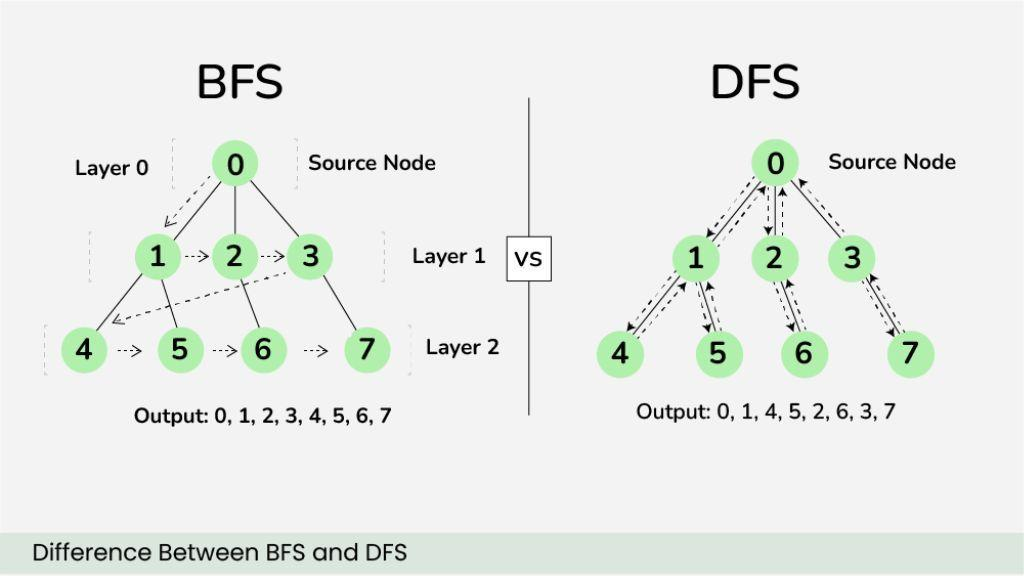

### What is a Graph?
A graph is a mathematical structure used to model pairwise relationships between objects. It is composed of:
* **Nodes (Vertices):** Represent the entities in the graph.
* **Edges:** Represent the connections or relationships between pairs of nodes.

In [1]:
class Node():
    """Represents a single node (vertex) in the graph with a specific name."""
    def __init__(self, name=None) -> None:
        self.name = name

    def get_name(self):
        """Returns the name of the node."""
        return self.name

    def __str__(self) -> str:
        return self.name

    def __repr__(self) -> str:
        return self.name


class Edge():
    """Represents a directed edge connecting a source node to a destination node."""
    def __init__(self, src, dst) -> None:
        self.src = src
        self.dst = dst

    def get_source(self):
        """Returns the starting node of the edge."""
        return self.src

    def get_destination(self):
        """Returns the destination node of the edge."""
        return self.dst

    def __str__(self) -> str:
        return self.src.get_name() + '->' + self.dst.get_name()


class DiGraph:
    """Represents a Directed Graph using an adjacency list model represented as a dictionary."""
    def __init__(self) -> None:
        # Maps each node to a list of its destination children
        self.edges = {}

    def add_node(self, node):
        """Adds a new node to the graph if it is not already present."""
        if node in self.edges:
            raise ValueError('Duplicate Nodes')
        else:
            self.edges[node] = []

    def add_edges(self, edge):
        """Adds a directed edge between two existing nodes."""
        src = edge.get_source()
        dst = edge.get_destination()
        if not (src in self.edges and dst in self.edges):
            raise ValueError('Node not in Graph')
        self.edges[src].append(dst)

    def children(self, node):
        """Returns a list of destination nodes connected from the given node."""
        return self.edges[node]

    def has_node(self, node):
        """Returns True if the node exists in the graph, False otherwise."""
        return node in self.edges

    def get_node(self, name):
        """Finds and returns a Node object in the graph by its string name."""
        for n in self.edges:
            if n.get_name() == name:
                return n
        raise NameError(name)

    def __str__(self) -> str:
        result = ''
        for src in self.edges:
            for dst in self.edges[src]:
                result = result + src.get_name() + '->' + dst.get_name() + '\n'
        return result[:-1]

In [2]:
# 1. Define the graph builder function
def build_complicated_city_graph(graph_type):
    """
    Creates and populates a graph with city nodes and a branching relationship structure
    where certain nodes contain multiple children (outward edges).
    """
    g = graph_type()

    # Add all cities as nodes to the graph
    for node in ('Ardabil', 'Sarab', 'Tabriz', 'Xoi', 'Urmia', 'Sulduz', 'Soyug Bulag'):
        g.add_node(Node(node))

    # Multiple children for Ardabil: branches to both Sarab and Tabriz
    g.add_edges(Edge(g.get_node('Ardabil'), g.get_node('Sarab')))
    g.add_edges(Edge(g.get_node('Ardabil'), g.get_node('Tabriz')))

    # Sarab connects directly to Tabriz
    g.add_edges(Edge(g.get_node('Sarab'), g.get_node('Tabriz')))

    # Multiple children for Tabriz: branches to both Xoi and Sulduz
    g.add_edges(Edge(g.get_node('Tabriz'), g.get_node('Xoi')))
    g.add_edges(Edge(g.get_node('Tabriz'), g.get_node('Sulduz')))

    # Linear routes and cyclic loops below Tabriz
    g.add_edges(Edge(g.get_node('Xoi'), g.get_node('Urmia')))
    g.add_edges(Edge(g.get_node('Sulduz'), g.get_node('Urmia')))
    g.add_edges(Edge(g.get_node('Urmia'), g.get_node('Soyug Bulag')))
    g.add_edges(Edge(g.get_node('Soyug Bulag'), g.get_node('Sulduz')))
    return g

In [3]:
# 2. Instantiate the complicated graph and print its full structure
graph = build_complicated_city_graph(DiGraph)

print("--- Graph Adjacency List (Parent -> Children Structure) ---")
for parent_node in graph.edges:
    children_nodes = graph.children(parent_node)
    children_names = [child.get_name() for child in children_nodes]
    print(f"{parent_node.get_name()} -> {children_names}")

--- Graph Adjacency List (Parent -> Children Structure) ---
Ardabil -> ['Sarab', 'Tabriz']
Sarab -> ['Tabriz']
Tabriz -> ['Xoi', 'Sulduz']
Xoi -> ['Urmia']
Urmia -> ['Soyug Bulag']
Sulduz -> ['Urmia']
Soyug Bulag -> ['Sulduz']


In [4]:
# Helper functions to print paths
def print_path(path):
    return '->'.join([str(node) for node in path])

# Depth-First Search (DFS) Implementation
def dfs(graph, start, end, path, shortest, to_print=False):
    path = path + [start]
    if to_print:
        print('Current DFS path:', print_path(path))
    if start == end:
        return path
    for node in graph.children(start):
        if node not in path: # Avoid cycles
            if shortest == None or len(path) < len(shortest):
                new_path = dfs(graph, node, end, path, shortest, to_print)
                if new_path != None:
                    shortest = new_path
    return shortest

def short_path_dfs(graph, start, end, to_print=False):
    return dfs(graph, start, end, [], None, to_print)

# Test DFS Pathfinding on the Complicated Graph
def test_dfs(src: str, dst: str):
    graph = build_complicated_city_graph(DiGraph)
    shortest_path = short_path_dfs(
        graph,
        graph.get_node(src),
        graph.get_node(dst),
        to_print=True)
    if shortest_path != None:
        print(f"\nThe shortest DFS path from {src} to {dst} is {print_path(shortest_path)}")
    else:
        print(f"\nNo path found from {src} to {dst}")

test_dfs('Ardabil', 'Sulduz')

Current DFS path: Ardabil
Current DFS path: Ardabil->Sarab
Current DFS path: Ardabil->Sarab->Tabriz
Current DFS path: Ardabil->Sarab->Tabriz->Xoi
Current DFS path: Ardabil->Sarab->Tabriz->Xoi->Urmia
Current DFS path: Ardabil->Sarab->Tabriz->Xoi->Urmia->Soyug Bulag
Current DFS path: Ardabil->Sarab->Tabriz->Xoi->Urmia->Soyug Bulag->Sulduz
Current DFS path: Ardabil->Sarab->Tabriz->Sulduz
Current DFS path: Ardabil->Tabriz
Current DFS path: Ardabil->Tabriz->Xoi
Current DFS path: Ardabil->Tabriz->Xoi->Urmia
Current DFS path: Ardabil->Tabriz->Sulduz

The shortest DFS path from Ardabil to Sulduz is Ardabil->Tabriz->Sulduz


In [5]:
# Breadth-First Search (BFS) Implementation
def bfs(graph, start, end, to_print=False):
    init_path = [start]
    path_queue = [init_path]
    while len(path_queue) != 0:
        # Get and remove oldest element in queue
        tmp_path = path_queue.pop(0)
        if to_print:
            print('Current BFS path:', print_path(tmp_path))
        last_node = tmp_path[-1]
        if last_node == end:
            return tmp_path
        for next_node in graph.children(last_node):
            if next_node not in tmp_path:
                new_path = tmp_path + [next_node]
                path_queue.append(new_path)
    return None

# Test BFS Pathfinding on the Complicated Graph
def test_bfs(src: str, dst: str):
    graph = build_complicated_city_graph(DiGraph)
    shortest_path = bfs(
        graph,
        graph.get_node(src),
        graph.get_node(dst),
        to_print=True)
    if shortest_path != None:
        print(f"\nThe shortest BFS path from {src} to {dst} is {print_path(shortest_path)}")
    else:
        print(f"\nNo path found from {src} to {dst}")

test_bfs('Ardabil', 'Sulduz')

Current BFS path: Ardabil
Current BFS path: Ardabil->Sarab
Current BFS path: Ardabil->Tabriz
Current BFS path: Ardabil->Sarab->Tabriz
Current BFS path: Ardabil->Tabriz->Xoi
Current BFS path: Ardabil->Tabriz->Sulduz

The shortest BFS path from Ardabil to Sulduz is Ardabil->Tabriz->Sulduz


DFS (Depth-First Search) is useful when:
- Exploring deep paths.
- Searching for any possible solution.
- Backtracking through different possibilities.
- Working with memory constraints in certain graph structures.

---


BFS (Breadth-First Search) is useful when:







- Finding the shortest path in an unweighted graph.
- Searching for the nearest matching node.
- Exploring nodes level by level.